# Does filling cloud gaps help land-cover classification? Where does it mislead?
**Visual Computing with AI/ML (AI61201)** · P. Sai Dharanidhar Ram (24AI10004), Ruthvik Devarakonda (24AI10023)

This notebook **loads the already-trained models** (no training) and shows: (1) saved results, (2) a live demo on any test image, (3) a re-run that reproduces the headline table, (4) the failure gallery.

Scope: land-cover only. Fills are *plausible content, not the true scene*. Clouds are **synthetic** (white, on 64×64 EuroSAT tiles).

## 0. Setup

In [1]:
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Run from the folder that CONTAINS cloud_removal_project/
if not Path("cloud_removal_project").exists() and Path("src").exists():
    os.chdir("..")
ROOT = Path("cloud_removal_project")
assert ROOT.exists(), "Place this notebook in the folder that contains cloud_removal_project/"
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import torchvision.transforms as T
from PIL import Image
from IPython.display import display, Markdown

from classifier import get_classifier, NORM_MEAN, NORM_STD
from unet_inpaint import SmallUNetInpainter
from cloud_simulation import CloudSimulator
import inpainting_baselines as B

device = "cuda" if torch.cuda.is_available() else "cpu"
CLASSES = ['AnnualCrop','Forest','HerbaceousVegetation','Highway','Industrial',
           'Pasture','PermanentCrop','Residential','River','SeaLake']
print("device:", device)

device: cpu


## 1. Load the trained models

In [2]:
def load_clf(path):
    m = get_classifier(num_classes=10, pretrained=False)
    m.load_state_dict(torch.load(ROOT / path, map_location=device))
    return m.to(device).eval()

classifiers = {
    "clean":      load_clf("models/resnet18_clean.pth"),        # trained on clean images only
    "mask_aware": load_clf("models/resnet18_mask_aware.pth"),   # adapted to masked (zeroed) gaps
    "fill_aware": load_clf("models/resnet18_fill_aware.pth"),   # adapted to filled gaps
}
unet = SmallUNetInpainter().to(device)
unet.load_state_dict(torch.load(ROOT / "models/unet_inpaint.pth", map_location=device))
unet.eval()

tf = T.Compose([T.ToTensor(), T.Normalize(mean=NORM_MEAN, std=NORM_STD)])

@torch.no_grad()
def predict(img_uint8, model):
    logits = model(tf(Image.fromarray(img_uint8)).unsqueeze(0).to(device))
    p = logits.argmax(1).item()
    return p, torch.softmax(logits, 1)[0, p].item()

@torch.no_grad()
def inpaint_unet(cloudy, mask):
    x = torch.from_numpy(cloudy).permute(2, 0, 1).unsqueeze(0).float().div(255).to(device)
    m = torch.from_numpy(mask).unsqueeze(0).unsqueeze(0).float().to(device)
    o = unet(x, m).squeeze(0).permute(1, 2, 0).cpu().numpy()
    return (o * 255).clip(0, 255).astype(np.uint8)

METHODS = ["cloudy_as_is", "masked", "mean_fill", "nearest_neighbor", "telea_inpaint", "unet"]
def make_outputs(cloudy, mask):
    return {
        "cloudy_as_is": B.cloudy_as_is(cloudy, mask),
        "masked": B.masked_input(cloudy, mask, fill_value=0),
        "mean_fill": B.mean_fill(cloudy, mask),
        "nearest_neighbor": B.nearest_neighbor_fill(cloudy, mask),
        "telea_inpaint": B.telea_inpaint(cloudy, mask),
        "unet": inpaint_unet(cloudy, mask),
    }
print("models loaded")

models loaded


## 2. Saved results (from `evaluate_all.py`)
Three classifiers: **clean** (trained on clean images), **mask_aware** (adapted to masked gaps), **fill_aware** (adapted to filled gaps). Adapted classifiers were trained on a *different mask family* than the test clouds.

In [3]:
RES = ROOT / "results"
acc = pd.read_csv(RES / "downstream_accuracy_table.csv")
for clf in ["clean", "mask_aware", "fill_aware"]:
    display(Markdown(f"**Accuracy (%) — classifier = {clf}**"))
    sub = acc[acc["classifier"] == clf]
    display(sub.pivot(index="method", columns=["condition", "coverage_bin"], values="accuracy_pct").round(1))

**Accuracy (%) — classifier = clean**

condition        semi_transparent  thick              
coverage_bin               30-60% 10-30% 30-60% 60-80%
method                                                
cloudy_as_is                 62.0   71.0   43.0   17.0
masked                       20.5   44.5   20.5   14.0
mean_fill                    50.0   87.5   52.5   13.0
nearest_neighbor             77.0   94.0   81.5   40.5
telea_inpaint                61.5   91.5   57.5   23.0
unet                         40.0   92.0   56.0   21.0

**Accuracy (%) — classifier = mask_aware**

condition        semi_transparent  thick              
coverage_bin               30-60% 10-30% 30-60% 60-80%
method                                                
cloudy_as_is                 67.0   64.0   31.5   13.5
masked                       81.0   88.5   85.5   68.0
mean_fill                    37.0   79.5   41.5   13.5
nearest_neighbor             71.0   93.0   70.5   39.0
telea_inpaint                58.5   87.5   56.0   25.5
unet                         69.5   91.0   59.0   29.5

**Accuracy (%) — classifier = fill_aware**

condition        semi_transparent  thick              
coverage_bin               30-60% 10-30% 30-60% 60-80%
method                                                
cloudy_as_is                 58.0   58.0   41.5   15.5
masked                       20.0   36.5   16.5   13.0
mean_fill                    87.5   93.5   92.0   80.5
nearest_neighbor             91.5   96.0   93.0   84.5
telea_inpaint                92.5   93.5   94.0   83.5
unet                         32.5   94.5   94.5   84.5

In [4]:
display(Markdown("**Fair comparison:** masked input + mask-aware classifier vs fill + fill-aware classifier (paired bootstrap, 95% CI of accuracy difference)"))
pc = pd.read_csv(RES / "paired_comparison.csv")
display(pc.round(3))

**Fair comparison:** masked input + mask-aware classifier vs fill + fill-aware classifier (paired bootstrap, 95% CI of accuracy difference)

,condition,coverage_bin,fill_method,fill_aware_acc,masked_mask_aware_acc,diff_fill_minus_masked,diff_ci_low,diff_ci_high
0,semi_transparent,30-60%,mean_fill,0.875,0.810,0.065,0.010,0.125
1,semi_transparent,30-60%,nearest_neighbor,0.915,0.810,0.105,0.055,0.155
2,semi_transparent,30-60%,telea_inpaint,0.925,0.810,0.115,0.060,0.175
3,semi_transparent,30-60%,unet,0.325,0.810,-0.485,-0.560,-0.405
4,thick,10-30%,mean_fill,0.935,0.885,0.050,0.005,0.100
5,thick,10-30%,nearest_neighbor,0.960,0.885,0.075,0.030,0.125
6,thick,10-30%,telea_inpaint,0.935,0.885,0.050,0.005,0.095
7,thick,10-30%,unet,0.945,0.885,0.060,0.020,0.105
8,thick,30-60%,mean_fill,0.920,0.855,0.065,0.015,0.120
9,thick,30-60%,nearest_neighbor,0.930,0.855,0.075,0.020,0.135


In [5]:
display(Markdown("**Where harmful flips go (fills only, standard classifier): share predicted SeaLake/River**"))
ps = pd.read_csv(RES / "prediction_shift_fills.csv")
display(ps)
display(Markdown("**Do PSNR / SSIM / LPIPS detect the failures? (Spearman ρ)**"))
display(pd.read_csv(RES / "metric_validity.csv").round(3))

**Where harmful flips go (fills only, standard classifier): share predicted SeaLake/River**

,method,coverage_bin,n_rows,harmful_flips,harmful_rate_%,share_into_SeaLake_or_River_%,top_wrong_class
0,mean_fill,10-30%,200,21,10.5,19.0,Pasture
1,mean_fill,30-60%,200,90,45.0,92.2,SeaLake
2,mean_fill,60-80%,200,169,84.5,100.0,SeaLake
3,nearest_neighbor,10-30%,200,8,4.0,0.0,PermanentCrop
4,nearest_neighbor,30-60%,200,33,16.5,18.2,AnnualCrop
5,nearest_neighbor,60-80%,200,114,57.0,56.1,River
6,telea_inpaint,10-30%,200,13,6.5,7.7,AnnualCrop
7,telea_inpaint,30-60%,200,82,41.0,73.2,SeaLake
8,telea_inpaint,60-80%,200,149,74.5,85.2,SeaLake
9,unet,10-30%,200,12,6.0,8.3,AnnualCrop


**Do PSNR / SSIM / LPIPS detect the failures? (Spearman ρ)**

,metric,pooled_spearman_rho,pooled_p_value,within_bin_30_60_rho,within_bin_p_value,rho_vs_harmful_flips
0,psnr_full,0.237,0.0,0.034,0.338,-0.230
1,psnr_mask,0.113,0.0,-0.012,0.734,-0.104
2,ssim_full,0.441,0.0,0.231,0.000,-0.442
3,ssim_mask,0.190,0.0,0.111,0.002,-0.184
4,lpips,-0.527,0.0,-0.347,0.000,0.533


## 3. Figures

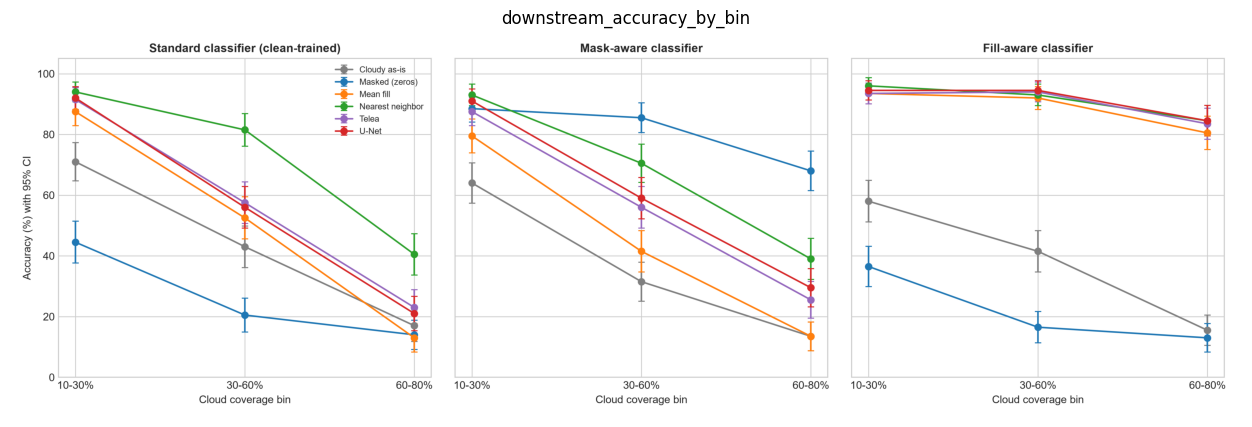

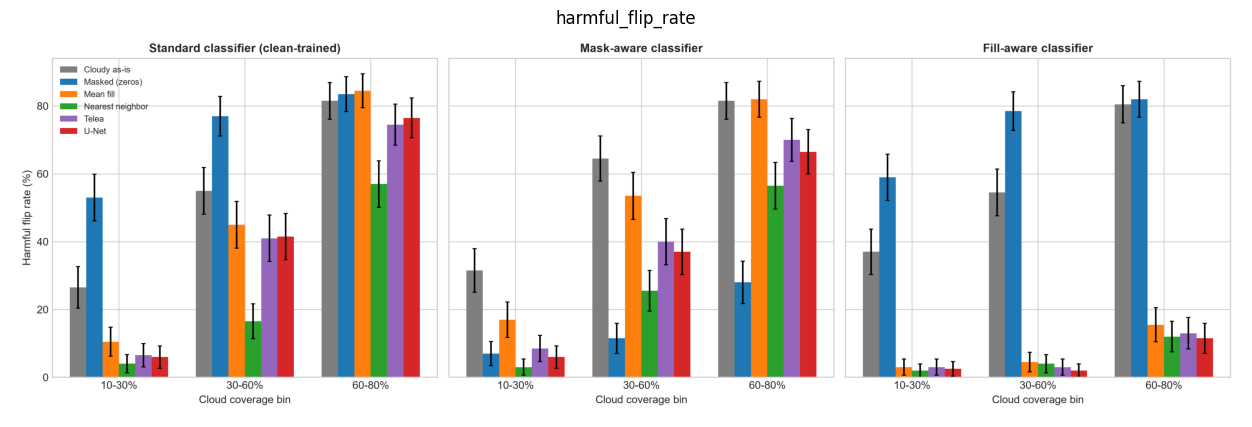

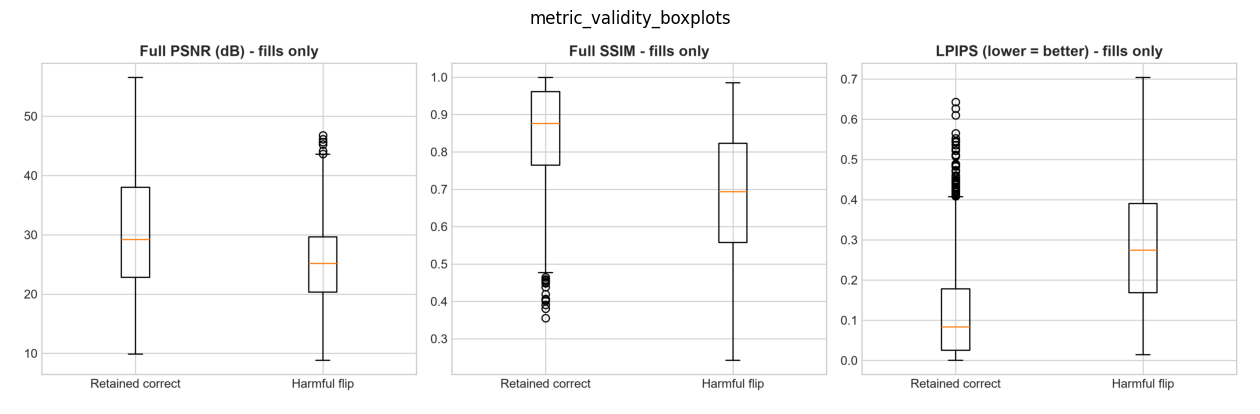

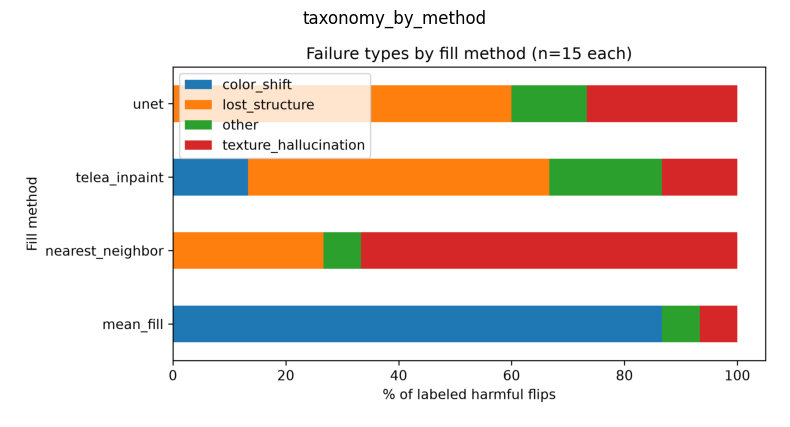

In [6]:
for name in ["downstream_accuracy_by_bin", "harmful_flip_rate", "metric_validity_boxplots", "taxonomy_by_method"]:
    p = RES / "figures" / f"{name}.png"
    if p.exists():
        plt.figure(figsize=(16, 5)); plt.imshow(plt.imread(p)); plt.axis("off"); plt.title(name); plt.show()

## 4. Live demo
Pick a test image, a cloud-coverage bin and a seed. Each output is classified by all three classifiers
(✓ = correct, ✗ = wrong, with the predicted class).

In [7]:
test_df = pd.read_csv(ROOT / "data/splits/test.csv")
sim = CloudSimulator(64, 64)
BINS = {"10-30%": (0.10, 0.30), "30-60%": (0.30, 0.60), "60-80%": (0.60, 0.80)}
SHORT = {"clean": "std", "mask_aware": "mask", "fill_aware": "fill"}

def run_demo(class_name="Residential", example=0, bin_name="60-80%", condition="thick", seed=0):
    sub = test_df[test_df["class_name"] == class_name].reset_index(drop=True)
    row = sub.iloc[example % len(sub)]
    clean = np.array(Image.open(ROOT / row["rel_path"]).convert("RGB"))
    rng = np.random.default_rng(seed)
    mask = sim.generate_cloud_mask(BINS[bin_name], rng=rng)
    cloudy, desc = sim.apply_cloud(clean, mask, condition=condition, rng=rng)
    outs = make_outputs(cloudy, mask)
    panels = [("clean", clean)] + [(m, outs[m]) for m in METHODS]

    table, fig, axes = {}, plt.figure(figsize=(19, 3.6)), None
    for i, (name, img) in enumerate(panels):
        ax = fig.add_subplot(1, len(panels), i + 1); ax.imshow(img); ax.axis("off")
        lines = [name]
        for cn, model in classifiers.items():
            p, conf = predict(img, model)
            ok = "✓" if p == int(row["label"]) else "✗"
            lines.append(f"{SHORT[cn]}: {ok} {CLASSES[p][:9]}")
            table.setdefault(name, {})[cn] = f"{ok} {CLASSES[p]} ({conf:.2f})"
        ax.set_title("\n".join(lines), fontsize=8)
    fig.suptitle(f"true class: {row['class_name']} | {condition} | coverage {desc['coverage_pct']*100:.0f}%", y=1.08)
    plt.show()
    display(pd.DataFrame(table).T)

try:
    from ipywidgets import interact, Dropdown, IntSlider
    interact(run_demo,
             class_name=Dropdown(options=CLASSES, value="Residential"),
             example=IntSlider(min=0, max=50, value=0),
             bin_name=Dropdown(options=list(BINS), value="60-80%"),
             condition=Dropdown(options=["thick", "semi_transparent"], value="thick"),
             seed=IntSlider(min=0, max=50, value=0));
except ImportError:
    run_demo()   # pip install ipywidgets for the interactive version

interactive(children=(Dropdown(description='class_name', index=7, options=('AnnualCrop', 'Forest', 'Herbaceous…

## 5. Reproduce the headline table from the loaded models
Re-runs the evaluation (same sampling and seeds as `evaluate_all.py`) with the saved checkpoints, and compares with the saved CSV. Takes about a minute on GPU.

In [8]:
N_EVAL = 200
COND = [("thick", "10-30%", (0.10, 0.30)), ("thick", "30-60%", (0.30, 0.60)),
        ("thick", "60-80%", (0.60, 0.80)), ("semi_transparent", "30-60%", (0.30, 0.60))]

per_class = max(1, N_EVAL // 10)
subs = [test_df[test_df["class_name"] == c].sample(min((test_df["class_name"] == c).sum(), per_class), random_state=42)
        for c in sorted(test_df["class_name"].unique())]
sampled = pd.concat(subs).sample(frac=1.0, random_state=42).reset_index(drop=True)

rec = []
for idx, row in sampled.iterrows():
    clean = np.array(Image.open(ROOT / row["rel_path"]).convert("RGB"))
    rng = np.random.default_rng(42 + idx)
    for cond, bname, brange in COND:
        mask = sim.generate_cloud_mask(brange, rng=rng)
        cloudy, _ = sim.apply_cloud(clean, mask, condition=cond, rng=rng)
        for m, img in make_outputs(cloudy, mask).items():
            for cn, model in classifiers.items():
                rec.append((cn, cond, bname, m, int(predict(img, model)[0] == int(row["label"]))))

rep = (pd.DataFrame(rec, columns=["classifier", "condition", "coverage_bin", "method", "ok"])
       .groupby(["classifier", "condition", "coverage_bin", "method"])["ok"].mean().mul(100).round(1).reset_index(name="reproduced_%"))
cmp_ = rep.merge(acc[["classifier", "condition", "coverage_bin", "method", "accuracy_pct"]],
                 on=["classifier", "condition", "coverage_bin", "method"])
cmp_["saved_%"] = cmp_["accuracy_pct"].round(1)
cmp_["abs_diff"] = (cmp_["reproduced_%"] - cmp_["saved_%"]).abs()
print("max |difference| vs saved table (points):", cmp_["abs_diff"].max())
display(cmp_[(cmp_["condition"] == "thick") & (cmp_["coverage_bin"] == "60-80%")]
        .drop(columns=["accuracy_pct"]).sort_values(["classifier", "method"]))

max |difference| vs saved table (points): 0.0


,classifier,condition,coverage_bin,method,reproduced_%,saved_%,abs_diff
18,clean,thick,60-80%,cloudy_as_is,17.0,17.0,0.0
19,clean,thick,60-80%,masked,14.0,14.0,0.0
20,clean,thick,60-80%,mean_fill,13.0,13.0,0.0
21,clean,thick,60-80%,nearest_neighbor,40.5,40.5,0.0
22,clean,thick,60-80%,telea_inpaint,23.0,23.0,0.0
23,clean,thick,60-80%,unet,21.0,21.0,0.0
42,fill_aware,thick,60-80%,cloudy_as_is,15.5,15.5,0.0
43,fill_aware,thick,60-80%,masked,13.0,13.0,0.0
44,fill_aware,thick,60-80%,mean_fill,80.5,80.5,0.0
45,fill_aware,thick,60-80%,nearest_neighbor,84.5,84.5,0.0


## 6. Failure gallery (manually labeled harmful flips)
Each montage: clean | cloudy | fill | mask. Label = the most visible problem in the fill.

manual_label,color_shift,lost_structure,other,texture_hallucination
method,,,,
mean_fill,13,0,1,1
nearest_neighbor,0,4,1,10
telea_inpaint,2,8,3,2
unet,0,9,2,4


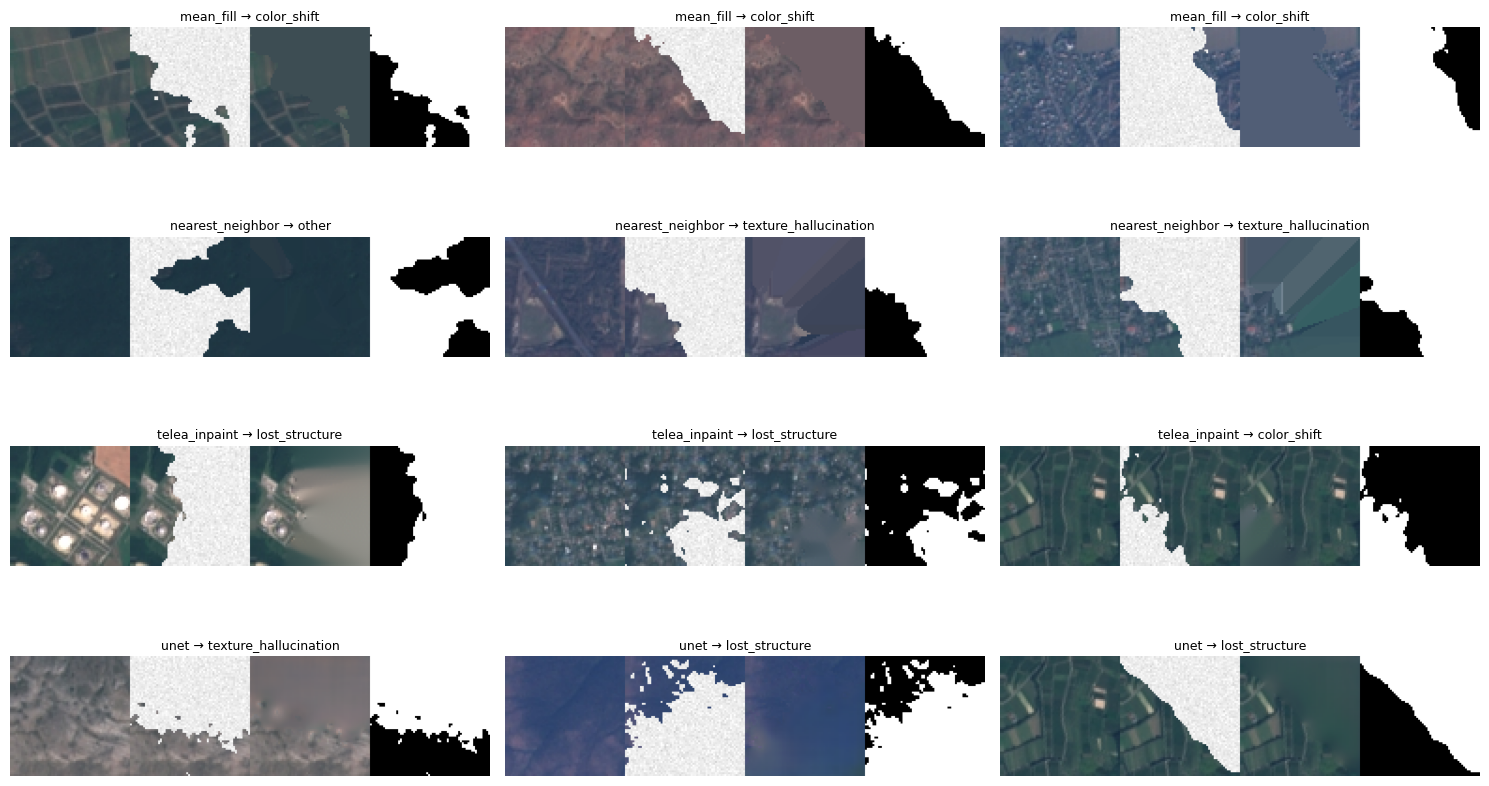

In [9]:
sheet = pd.read_csv(RES / "manual_label_sheet.csv")
sheet = sheet[sheet["manual_label"].notna() & (sheet["manual_label"].astype(str).str.len() > 0)]
display(pd.crosstab(sheet["method"], sheet["manual_label"]))

methods_f = ["mean_fill", "nearest_neighbor", "telea_inpaint", "unet"]
fig, axes = plt.subplots(len(methods_f), 3, figsize=(15, 9))
for r, m in enumerate(methods_f):
    s = sheet[sheet["method"] == m].sample(min(3, (sheet["method"] == m).sum()), random_state=1)
    for c in range(3):
        ax = axes[r, c]; ax.axis("off")
        if c < len(s):
            ax.imshow(plt.imread(ROOT / s.iloc[c]["audit_image"]))
            ax.set_title(f"{m} → {s.iloc[c]['manual_label']}", fontsize=9)
plt.tight_layout(); plt.show()

## 7. Headline numbers (read from the CSVs)

In [ ]:
h = pc[(pc["condition"] == "thick") & (pc["coverage_bin"] == "60-80%")]
for _, r in h.iterrows():
    print(f"{r['fill_method']:>17}: fill+fill-aware {r['fill_aware_acc']*100:5.1f}% vs masked+mask-aware {r['masked_mask_aware_acc']*100:5.1f}%  "
          f"(diff {r['diff_fill_minus_masked']*100:+.1f} pts, 95% CI [{r['diff_ci_low']*100:+.1f}, {r['diff_ci_high']*100:+.1f}])")

        mean_fill: fill+fill-aware  80.5% vs masked+mask-aware  68.0%  (diff +12.5 pts, 95% CI [+6.5, +18.5])
 nearest_neighbor: fill+fill-aware  84.5% vs masked+mask-aware  68.0%  (diff +16.5 pts, 95% CI [+10.5, +23.0])
    telea_inpaint: fill+fill-aware  83.5% vs masked+mask-aware  68.0%  (diff +15.5 pts, 95% CI [+9.0, +22.0])
             unet: fill+fill-aware  84.5% vs masked+mask-aware  68.0%  (diff +16.5 pts, 95% CI [+10.0, +23.0])


: 

### Takeaways
1. **Fills only help if the classifier is adapted to them.** With the standard classifier, fills collapse at thick coverage (mean fill → mostly SeaLake).
2. **At 60–80% thick cloud, adapted classifiers on fills beat masking** (see paired CIs above); masking with a mask-aware classifier is still a strong baseline.
3. **Methods fail differently**: mean fill → colour shift; textured/inpainting methods → lost structure or invented texture.
4. **LPIPS tracks harmful flips better than PSNR/SSIM.**

### Limitations
Synthetic white clouds · 64×64 RGB tiles · small U-Net · adapted classifiers see fills from known methods · manual labels from one labeler (15 per method).